Urządzenie: cpu
--- Sprawdzenie generatora ---
Pozycje znaczników (0-indeksowane): [12 17]
Pozycje wskazywanych wartości (t-8): [4 9]
Wskazane wartości: [0.4236548 0.3834415]
Obliczona suma: 0.8071
Cel wygenerowany przez funkcję: 0.8071


--- Trening dla sekwencji L=50 ---
Baseline (stała predykcja): MSE=0.1598
SimpleRNN_h32   | MSE=0.1604 | czas= 6.9s | params=1185
LSTM_h32        | MSE=0.1599 | czas=11.2s | params=4641
GRU_h32         | MSE=0.1428 | czas=18.1s | params=3489
Conv1D_d124     | MSE=0.1568 | czas=10.3s | params=6465

--- Trening dla sekwencji L=100 ---
Baseline (stała predykcja): MSE=0.1667
SimpleRNN_h32   | MSE=0.1671 | czas=12.3s | params=1185
LSTM_h32        | MSE=0.1666 | czas=19.5s | params=4641
GRU_h32         | MSE=0.1656 | czas=33.6s | params=3489
Conv1D_d124     | MSE=0.1673 | czas=18.4s | params=6465
SimpleRNN_h64   | MSE=0.1672 | czas=19.7s | params=4417
Conv1D_d111     | MSE=0.1639 | czas=15.2s | params=6465

--- Analiza trudnego przypadku (SimpleRNN_h32, L=1

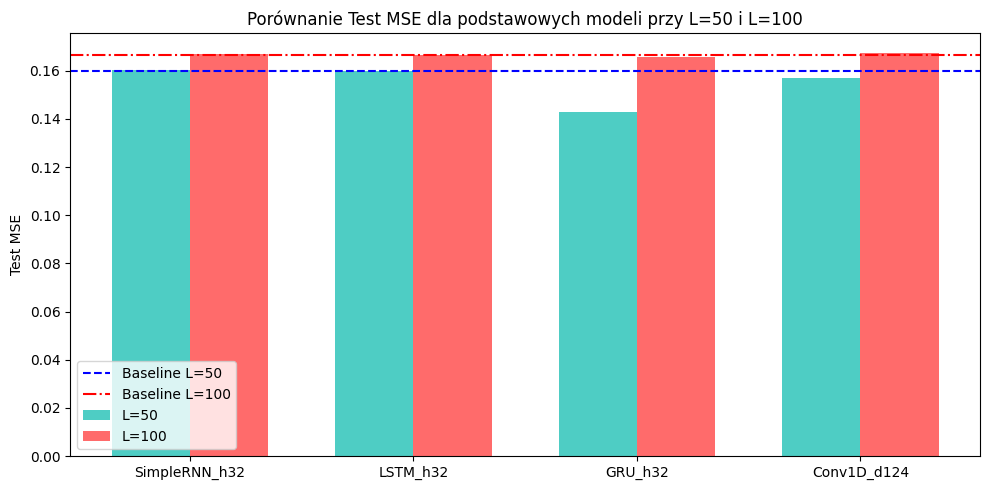

In [1]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Urządzenie:', DEVICE)

def gen_delayed(N, L):
    val = np.random.uniform(0, 1, (N, L, 1)).astype(np.float32)
    mark = np.zeros((N, L, 1), dtype=np.float32)
    y = np.zeros((N, 1), dtype=np.float32)

    for i in range(N):
        p = np.random.choice(np.arange(8, L), 2, replace=False)
        mark[i, p, 0] = 1.0
        y[i, 0] = val[i, p - 8, 0].sum()

    x = np.concatenate([val, mark], axis=2)  # [N, L, 2]
    return torch.tensor(x).to(DEVICE), torch.tensor(y).to(DEVICE)

xx, yy = gen_delayed(1, 20)
poz = np.where(xx[0, :, 1].cpu().numpy() == 1)[0]
wskazane_poz = poz - 8
wartosci = xx[0, wskazane_poz, 0].cpu().numpy()
suma = wartosci.sum()

print("sprawdzenie generatora")
print(f"Pozycje znaczników (0-indeksowane): {poz}")
print(f"Pozycje wskazywanych wartości (t-8): {wskazane_poz}")
print(f"Wskazane wartości: {wartosci}")
print(f"Obliczona suma: {suma:.4f}")
print(f"Cel wygenerowany przez funkcję: {float(yy[0, 0]):.4f}\n")

#modeli
class RNNNet(nn.Module):
    def __init__(self, typ, hidden=32):
        super().__init__()
        self.rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ](2, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

class ConvNet(nn.Module):
    def __init__(self, dilations, ch=32):
        super().__init__()
        layers = []
        in_ch = 2
        for d in dilations:
            pad = d * (3 - 1) // 2
            layers.append(nn.Conv1d(in_ch, ch, 3, padding=pad, dilation=d))
            layers.append(nn.ReLU())
            in_ch = ch

        self.net = nn.Sequential(*layers)
        self.fc = nn.Linear(ch, 1)

    def forward(self, x):
        h = self.net(x.transpose(1, 2)).mean(dim=2)
        return self.fc(h)

def licz_parametry(m):
    return sum(p.numel() for p in m.parameters())

#trening
def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30, batch=128, lr=5e-3):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    Lf = nn.MSELoss()
    N = Xtr.shape[0]

    t0 = time.time()
    for ep in range(epoki):
        model.train()
        perm = torch.randperm(N)
        for i in range(0, N, batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            Lf(model(Xtr[idx]), Ytr[idx]).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
    czas = time.time() - t0

    model.eval()
    with torch.no_grad():
        mse = Lf(model(Xte), Yte).item()
    return mse, czas

#eksperyment
wyniki = {'L=50': {}, 'L=100': {}}
N_train, N_test = 4000, 800

for L in [50, 100]:
    print(f"\n Trening dla sekwencji L={L}")
    Xtr, Ytr = gen_delayed(N_train, L)
    Xte, Yte = gen_delayed(N_test, L)

    mean_target = Ytr.mean().item()
    baseline_mse = torch.mean((Yte - mean_target)**2).item()
    wyniki[f'L={L}']['Baseline'] = {'mse': baseline_mse, 'czas': 0, 'params': 0}
    print(f"Baseline (stała predykcja): MSE={baseline_mse:.4f}")

    modele = {
        'SimpleRNN_h32': RNNNet('RNN', hidden=32),
        'LSTM_h32': RNNNet('LSTM', hidden=32),
        'GRU_h32': RNNNet('GRU', hidden=32),
        'Conv1D_d124': ConvNet(dilations=[1, 2, 4], ch=32)
    }

    if L == 100:
        modele['SimpleRNN_h64'] = RNNNet('RNN', hidden=64)
        modele['Conv1D_d111'] = ConvNet(dilations=[1, 1, 1], ch=32)

    for nazwa, m in modele.items():
        mse, czas = trenuj(m, Xtr, Ytr, Xte, Yte)
        params = licz_parametry(m)
        wyniki[f'L={L}'][nazwa] = {'mse': mse, 'czas': czas, 'params': params}
        print(f"{nazwa:15s} | MSE={mse:.4f} | czas={czas:4.1f}s | params={params}")

bad_model = modele['SimpleRNN_h32']
bad_model.eval()
with torch.no_grad():
    pred = bad_model(Xte[0:1])
    rzeczywista_suma = Yte[0:1].item()
    predykcja = pred.item()
    pozycje_zn = np.where(Xte[0, :, 1].cpu().numpy() == 1)[0]
    wartosci_wskaz = Xte[0, pozycje_zn - 8, 0].cpu().numpy()

print("\n analiza trudnego przypadku (SimpleRNN_h32, L=100)")
print(f"Pozycje znaczników: {pozycje_zn}")
print(f"Wskazane wartości: {wartosci_wskaz}")
print(f"Prawidłowa suma: {rzeczywista_suma:.4f}")
print(f"Predykcja modelu: {predykcja:.4f}")

modele_glowne = ['SimpleRNN_h32', 'LSTM_h32', 'GRU_h32', 'Conv1D_d124']
mse_L50 = [wyniki['L=50'][m]['mse'] for m in modele_glowne]
mse_L100 = [wyniki['L=100'][m]['mse'] for m in modele_glowne]

x = np.arange(len(modele_glowne))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width/2, mse_L50, width, label='L=50', color='#4ecdc4')
plt.bar(x + width/2, mse_L100, width, label='L=100', color='#ff6b6b')
plt.axhline(wyniki['L=50']['Baseline']['mse'], ls='--', color='blue', label='Baseline L=50')
plt.axhline(wyniki['L=100']['Baseline']['mse'], ls='-.', color='red', label='Baseline L=100')

plt.ylabel('Test MSE')
plt.title('Porównanie Test MSE dla podstawowych modeli przy L=50 i L=100')
plt.xticks(x, modele_glowne)
plt.legend()
plt.tight_layout()
plt.show()